In [8]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import warnings; warnings.filterwarnings("ignore")
import numpy as np

proc = "/nobackup/proj/comet_smmnfst/processed/"
adata = sc.read_h5ad(proc + "region1_macrophages.h5ad")
adata.obs["cell_type_fine"].value_counts()

cell_type_fine
Spinous keratinocyte                 4338
Basal keratinocyte                   3727
Fibroblast reticular (PI16+)         3263
Basal-to-spinous keratinocyte        3128
Endothelial blood                    2194
Schwann / nerve                      1897
Hair follicle ORS basal (SOX9+)      1751
Spinous keratinocyte upper           1558
T cell                               1516
Upper spinous / early granular       1309
Granular / cornified keratinocyte    1208
Basal keratinocyte proliferating      918
Fibroblast papillary (FAP+ DPP4+)     907
Subcluster_1                          678
Dendritic cell (cDC2)                 657
Subcluster_0                          633
Melanocyte                            593
Endothelial lymphatic                 399
Langerhans cell                       397
Mast cell                             241
Name: count, dtype: int64

In [10]:
sq.gr.ligrec(adata, cluster_key="cell_type_fine", use_raw=False, n_perms=1000, seed=0)

100%|██████████| 1000/1000 [03:31<00:00,  4.73permutation/s]


In [11]:


res = adata.uns["cell_type_fine_ligrec"]
pv, mn = res["pvalues"], res["means"]

rows = pv.index.to_frame(index=False);   rows.columns = ["ligand", "receptor"]
cols = pv.columns.to_frame(index=False); cols.columns = ["source", "target"]

sig = pd.DataFrame({
    "ligand":   np.repeat(rows["ligand"].values,   pv.shape[1]),
    "receptor": np.repeat(rows["receptor"].values, pv.shape[1]),
    "source":   np.tile(cols["source"].values,     pv.shape[0]),
    "target":   np.tile(cols["target"].values,     pv.shape[0]),
    "pvalue":   pv.values.ravel(),
    "mean":     mn.values.ravel(),
})
sig = sig[sig["pvalue"] < 0.01]
print(len(sig), "significant pair-combinations")

186422 significant pair-combinations


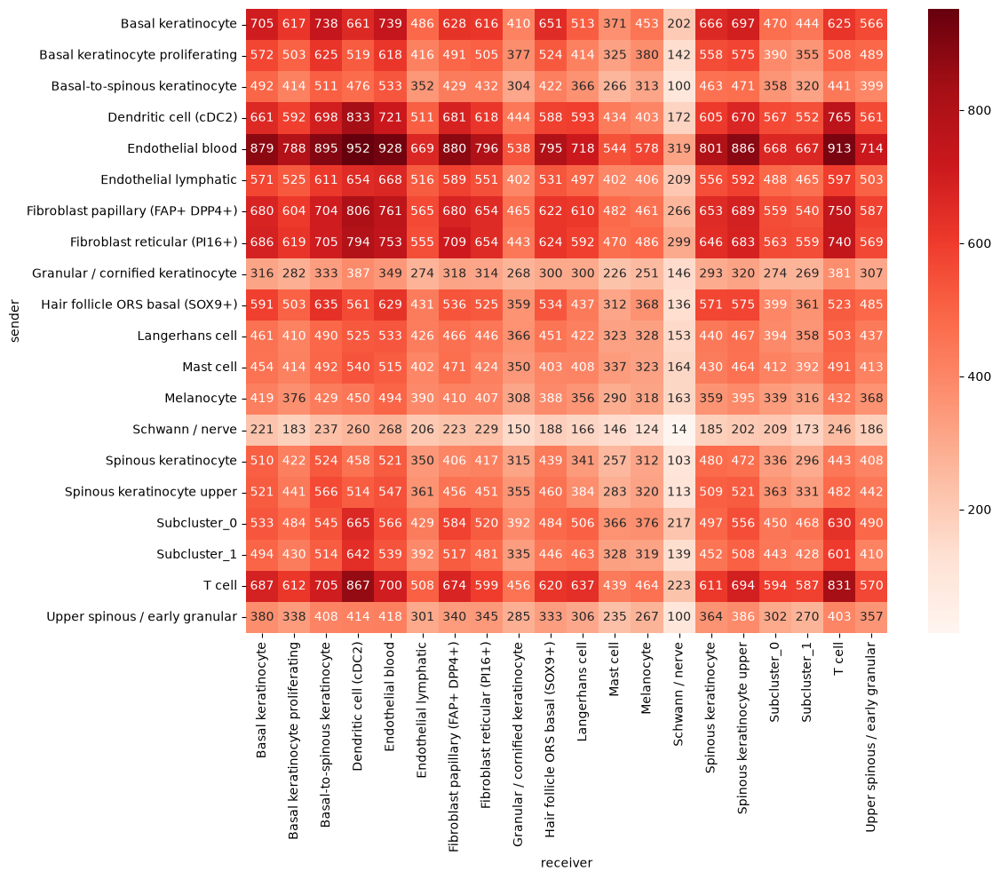

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
n_pairs = pd.crosstab(sig["source"], sig["target"])
plt.figure(figsize=(12, 10))
sns.heatmap(n_pairs, cmap="Reds", annot=True, fmt="d")
plt.xlabel("receiver"); plt.ylabel("sender"); plt.tight_layout()

In [14]:
sig.sort_values("mean", ascending=False).head(50)

,ligand,receptor,source,target,pvalue,mean
933206,FGFR3,CTSK,Basal keratinocyte,Fibroblast papillary (FAP+ DPP4+),0.0,1.620572
933506,FGFR3,CTSK,Spinous keratinocyte upper,Fibroblast papillary (FAP+ DPP4+),0.0,1.614387
933246,FGFR3,CTSK,Basal-to-spinous keratinocyte,Fibroblast papillary (FAP+ DPP4+),0.0,1.612059
880227,CTSG,CXCL12,Mast cell,Fibroblast reticular (PI16+),0.0,1.559139
933486,FGFR3,CTSK,Spinous keratinocyte,Fibroblast papillary (FAP+ DPP4+),0.0,1.539656
1081434,CTSG,THBD,Mast cell,Spinous keratinocyte,0.0,1.500799
800416,POSTN,STAB1,Basal keratinocyte,Subcluster_0,0.0,1.500277
1081422,CTSG,THBD,Mast cell,Basal-to-spinous keratinocyte,0.0,1.483018
933586,FGFR3,CTSK,Upper spinous / early granular,Fibroblast papillary (FAP+ DPP4+),0.0,1.465884
933226,FGFR3,CTSK,Basal keratinocyte proliferating,Fibroblast papillary (FAP+ DPP4+),0.0,1.457434





In [15]:
sq.pl.ligrec(adata, cluster_key="cell_type_fine", source_groups=["T cell"],
             alpha=0.01, pvalue_threshold=0.01)
sq.pl.ligrec(adata, cluster_key="cell_type_fine", target_groups=["Fibroblast papillary (FAP+ DPP4+)"],
             alpha=0.01, pvalue_threshold=0.01)

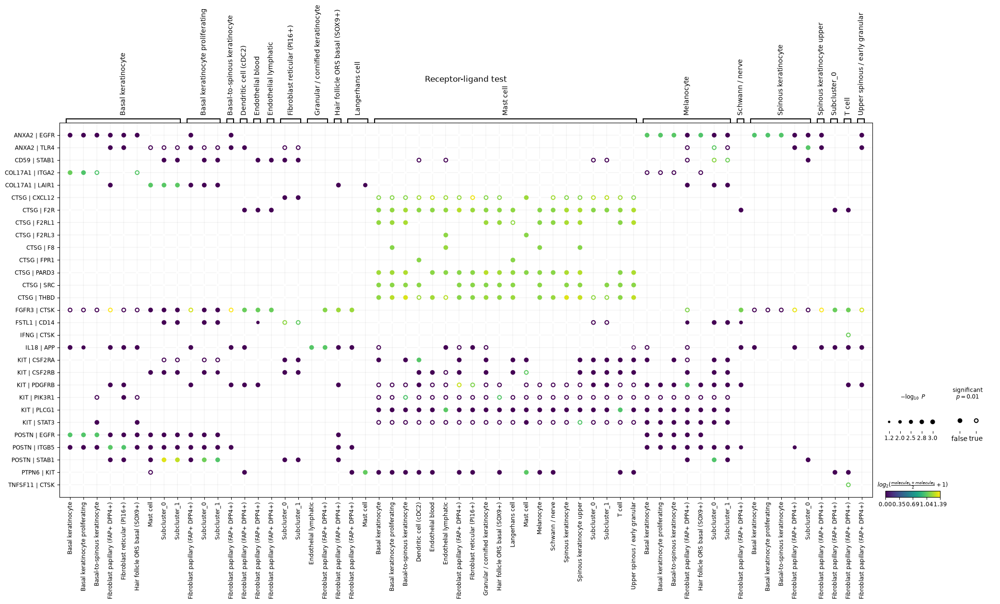

In [16]:
sq.pl.ligrec(adata, cluster_key="cell_type_fine", alpha=0.01, pvalue_threshold=0.01,
             means_range=(1.0, float("inf")))

,ligand,receptor,source,target,pvalue,mean
800416,POSTN,STAB1,Basal keratinocyte,Subcluster_0,0.0,1.500277
800417,POSTN,STAB1,Basal keratinocyte,Subcluster_1,0.0,1.398610
880237,CTSG,CXCL12,Mast cell,Subcluster_1,0.0,1.369528
880236,CTSG,CXCL12,Mast cell,Subcluster_0,0.0,1.358164
1081436,CTSG,THBD,Mast cell,Subcluster_0,0.0,1.230838
1081437,CTSG,THBD,Mast cell,Subcluster_1,0.0,1.229886
773356,FSTL1,CD14,Fibroblast reticular (PI16+),Subcluster_0,0.0,1.221103
831856,CD59,STAB1,Melanocyte,Subcluster_0,0.0,1.217379
1977437,CTSG,SRC,Mast cell,Subcluster_1,0.0,1.205658
227836,CTSG,F2R,Mast cell,Subcluster_0,0.0,1.204248








In [18]:
mac_states = ["Subcluster_0", "Subcluster_1"]
epi_labels = ["Basal-to-spinous keratinocyte", "Spinous keratinocyte upper", "Basal keratinocyte"]
targets = epi_labels + ["Fibroblast papillary (FAP+ DPP4+)", "Fibroblast reticular (PI16+)", "Endothelial blood"]

sq.pl.ligrec(adata, cluster_key="cell_type_fine", source_groups=mac_states, target_groups=targets,
             alpha=0.01, pvalue_threshold=0.01)
sq.pl.ligrec(adata, cluster_key="cell_type_fine", source_groups=targets + ["T cell"], target_groups=mac_states,
             alpha=0.01, pvalue_threshold=0.01)
macsig = sig[sig["source"].isin(mac_states) | sig["target"].isin(mac_states)].sort_values("mean", ascending=False)
macsig.head(40)

In [20]:
import pickle

ligrec_res = adata.uns.pop("cell_type_fine_ligrec")
with open(proc + "region1_ligrec_result.pkl", "wb") as f:
    pickle.dump(ligrec_res, f)

adata.write(proc + "region1_ligrec.h5ad")
sig.to_csv(proc + "ligrec_all_significant.csv", index=False)
macsig.to_csv(proc + "ligrec_macrophage_pairs.csv", index=False)